# 1. Préliminaires

## 1.1. Contexte
Il s'agit de s'exercer sur la regression linéaire avec un dataset de salaire.

## 1.2. Imports de librairies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

## 1.3. Chargement des données

In [6]:
data = pd.read_csv('data/salary_dataset.csv')
data.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


## 1.4. Structure et Typologie des données

In [7]:
# liste des colonnes
data.columns.to_list()

['Unnamed: 0', 'YearsExperience', 'Salary']

In [8]:
# suppression de la première colonne
data.drop(columns=["Unnamed: 0"],inplace=True)

In [9]:
# formattage du nom des colonnes
data.columns = [col.strip().lower() for col in data.columns]
data.columns

Index(['yearsexperience', 'salary'], dtype='str')

In [10]:
# affichage du nombre de lignes et de colonnes
data.shape

(30, 2)

In [11]:
# informations sur les colonnes
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   yearsexperience  30 non-null     float64
 1   salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


# 2.Exploration et Nettoyage

In [12]:
# verification de valeurs manquantes
data.isna().sum()

yearsexperience    0
salary             0
dtype: int64

In [13]:
# verification de valeurs nulles
data.isnull().sum()

yearsexperience    0
salary             0
dtype: int64

In [14]:
# verification de valeurs dupliquées
data.duplicated().sum()

np.int64(0)

In [15]:
# affichage des statistiques descriptives
data.describe()

,yearsexperience,salary
count,30.000000,30.000000
mean,5.413333,76004.000000
std,2.837888,27414.429785
min,1.200000,37732.000000
25%,3.300000,56721.750000
50%,4.800000,65238.000000
75%,7.800000,100545.750000
max,10.600000,122392.000000


# 3. Visualisations

Visualisons la repartition de l'année d'experience

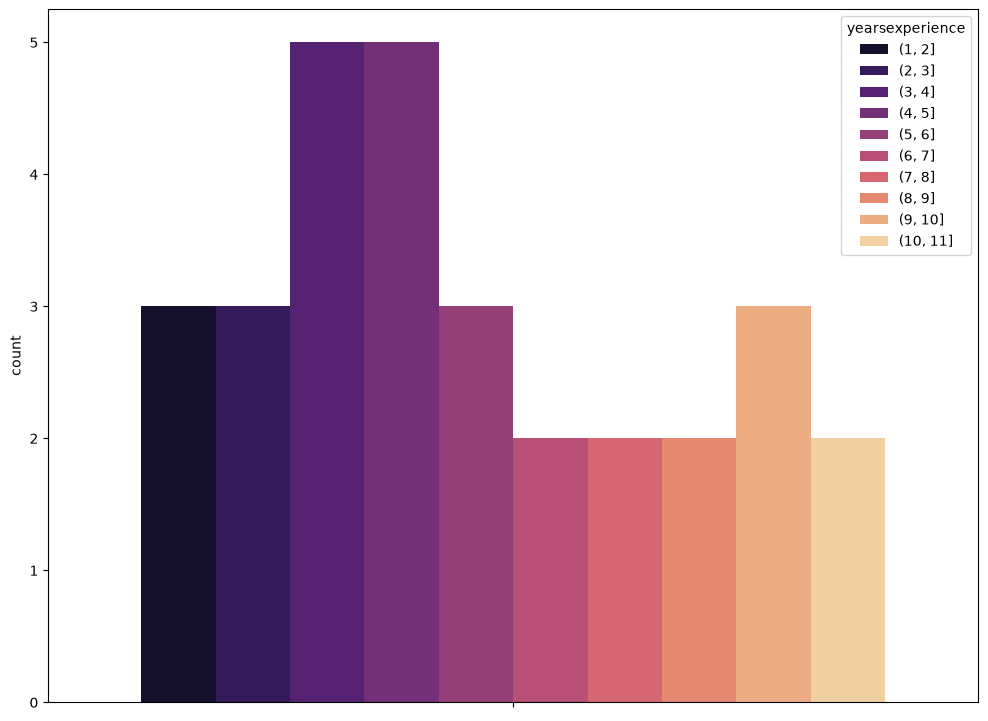

In [ ]:

plt.figure(figsize=(12,9))

yexp_bins = np.arange(1, 12, 1)

yexp = pd.cut(x=data["yearsexperience"], bins=yexp_bins.tolist()).value_counts().reset_index()

sns.barplot(data=yexp,hue="yearsexperience",y="count",palette="magma",errorbar=None)

plt.show()

La majorité semble avoir 3-5 ans d'experience

Visualisons la repartition du salaire

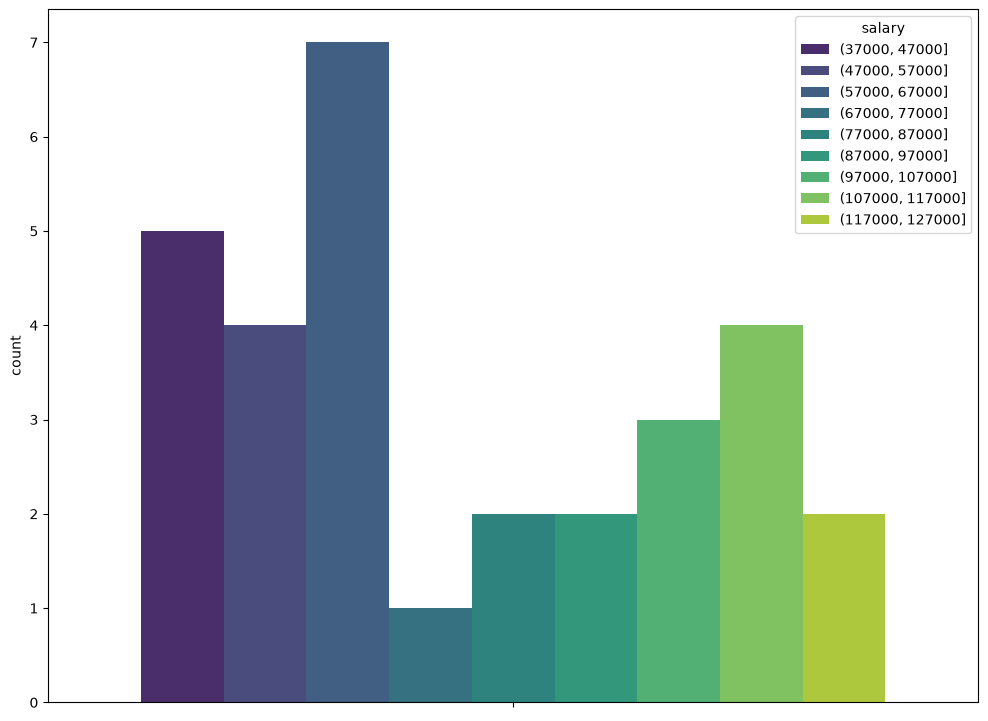

In [57]:
plt.figure(figsize=(12,9))

salary = pd.cut(x=data["salary"],bins=np.arange(37000,130000,10000).tolist()).value_counts().reset_index()

sns.barplot(data=salary,hue="salary",y="count",palette="viridis")

plt.show()

La plupart ont un salaire entre 57000 - 67000

Nuage de points

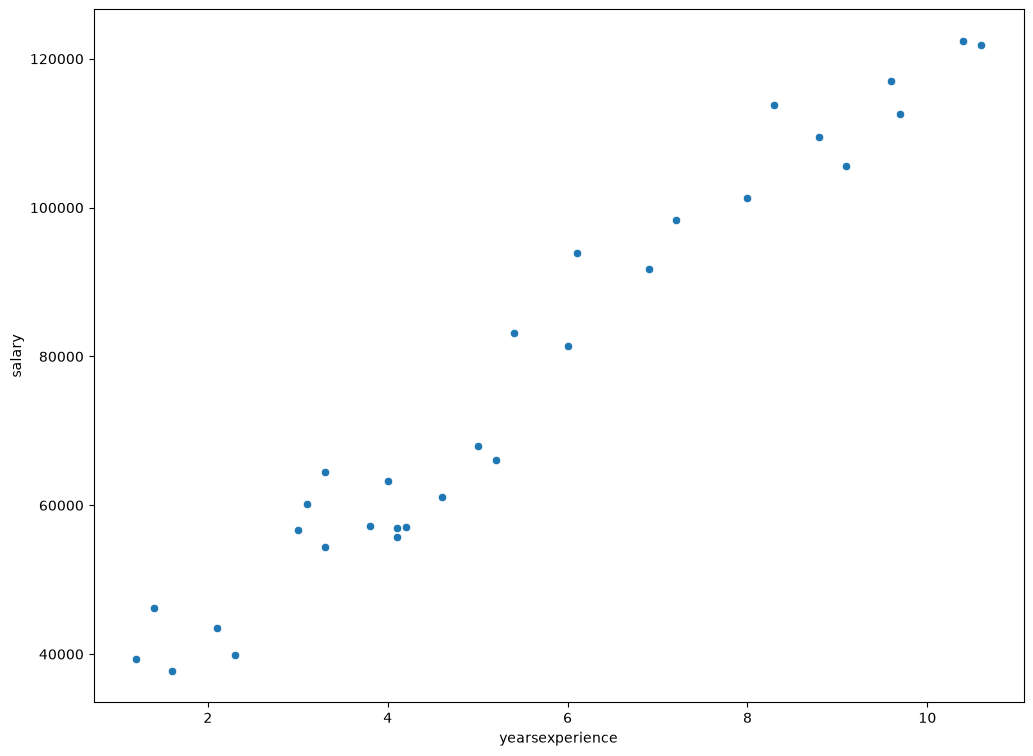

In [64]:
plt.figure(figsize=(12,9))
sns.scatterplot(data=data,x="yearsexperience",y="salary")
plt.show()

On remarque une nette correlation entre les deux variables

In [ ]:
# verification de la correlation
data.corr()

,yearsexperience,salary
yearsexperience,1.000000,0.978242
salary,0.978242,1.000000
